# Step 5: Predicting the target T from the context I (JEPA-style predictor)
Learn a predictor f: I -> T and measure how much of the target it recovers. All fitting / tuning uses TRAIN rows only; test rows are used only for the final numbers.

In [14]:
import json, random, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

from utils import load_split_data, get_split, COLOR_I, COLOR_T, COLOR_IT

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)

D = load_split_data()
_, _, groups_all = get_split()
I_tr, I_te, T_tr, T_te = D["I_tr"], D["I_te"], D["T_tr"], D["T_te"]
Y_tr, Y_te = D["Y_tr"], D["Y_te"]
g_tr, g_te = groups_all[D["train_idx"]], groups_all[D["test_idx"]]
print("train", I_tr.shape, "test", I_te.shape, "| train groups", len(np.unique(g_tr)), "test groups", len(np.unique(g_te)))
print("test labels unseen in train:", set(Y_te) - set(Y_tr))
Path("../results").mkdir(exist_ok=True); Path("../figures").mkdir(exist_ok=True)

train (2005, 512) test (495, 512) | train groups 1661 test groups 414
test labels unseen in train: set()


## 0. Evaluation protocol

In [15]:
def rownorm(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

def make_gallery(T, groups, Y):
    """Unique target vectors (one per group). Returns gallery G, gallery labels, row -> gallery index."""
    _, first, inv = np.unique(groups, return_index=True, return_inverse=True)
    return T[first], Y[first], inv

def ranks_for(P, T, groups, Y):
    """Per-row rank of the correct gallery target (1 = best), overall and within the same label."""
    G, gl, inv = make_gallery(T, groups, Y)
    S = rownorm(P) @ G.T
    correct = S[np.arange(len(S)), inv]
    rank = 1 + (S > correct[:, None]).sum(1)
    same = gl[None, :] == Y[:, None]
    wrank = 1 + ((np.where(same, S, -np.inf)) > correct[:, None]).sum(1)
    chance = (1.0 / same.sum(1))
    return rank, wrank, chance, len(G)

N_BOOT = 1000
def boot_ci(hits, boot_idx):
    m = hits.astype(float)[boot_idx].mean(1)
    return [float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))]

boot_idx = np.random.default_rng(SEED).integers(0, len(Y_te), (N_BOOT, len(Y_te)))

def evaluate(P, T=None, groups=None, Y=None, boot=True):
    """All metrics for raw predictions P against targets T (defaults: the test set)."""
    T = T_te if T is None else T; groups = g_te if groups is None else groups; Y = Y_te if Y is None else Y
    rank, wrank, chance, ng = ranks_for(P, T, groups, Y)
    out = dict(
        cos=float((rownorm(P) * T).sum(1).mean()),
        r2=float(r2_score(T, P, multioutput="variance_weighted")),
        top1=float((rank <= 1).mean()), top5=float((rank <= 5).mean()), top10=float((rank <= 10).mean()),
        median_rank=float(np.median(rank)),
        within_top1=float((wrank <= 1).mean()), within_chance=float(chance.mean()),
        gallery_size=int(ng), chance_top1=float(1 / ng),
    )
    if boot:
        out["top1_ci"] = boot_ci(rank <= 1, boot_idx)
        out["within_top1_ci"] = boot_ci(wrank <= 1, boot_idx)
    return out

def val_top1(P, T, groups, Y):
    return float((ranks_for(P, T, groups, Y)[0] <= 1).mean())

def show(name, m):
    ci = f" [{m['top1_ci'][0]:.3f},{m['top1_ci'][1]:.3f}]" if "top1_ci" in m else ""
    print(f"{name:<22} cos {m['cos']:.3f} | R2 {m['r2']:+.3f} | top1 {m['top1']:.3f}{ci} top5 {m['top5']:.3f} top10 {m['top10']:.3f} "
          f"| med.rank {m['median_rank']:.0f} | within-top1 {m['within_top1']:.3f} (chance {m['within_chance']:.3f})")

results = {}

## 1. Baselines (a–c; d follows the ridge CV because it needs the chosen alpha)

In [16]:
# a) mean target
P = np.tile(T_tr.mean(0), (len(T_te), 1))
results["mean_T"] = evaluate(P); show("mean T", results["mean_T"])

# b) raw context (no learning)
results["raw_I"] = evaluate(I_te); show("raw I", results["raw_I"])

# c) class-centroid ORACLE (uses the true test label -> cheating reference)
cent = {c: T_tr[Y_tr == c].mean(0) for c in np.unique(Y_tr)}
P = np.stack([cent[y] for y in Y_te])
results["class_oracle"] = evaluate(P); show("class oracle", results["class_oracle"])

mean T                 cos 0.001 | R2 -0.005 | top1 0.004 [0.000,0.010] top5 0.014 top10 0.024 | med.rank 209 | within-top1 0.073 (chance 0.078)
raw I                  cos 0.182 | R2 -0.643 | top1 0.091 [0.065,0.117] top5 0.335 top10 0.511 | med.rank 10 | within-top1 0.152 (chance 0.078)
class oracle           cos 0.549 | R2 +0.304 | top1 0.117 [0.089,0.145] top5 0.410 top10 0.582 | med.rank 8 | within-top1 0.119 (chance 0.078)


## 2. Ridge regression I -> T
Alpha chosen by 5-fold StratifiedGroupKFold on TRAIN (groups = identical-T ids), by validation top-1 within each fold's own validation gallery.

alpha 0.01   CV top-1 0.152 +- 0.008
alpha 0.1    CV top-1 0.163 +- 0.013
alpha 1      CV top-1 0.162 +- 0.015
alpha 10     CV top-1 0.153 +- 0.010
alpha 100    CV top-1 0.113 +- 0.008
chosen alpha: 0.1


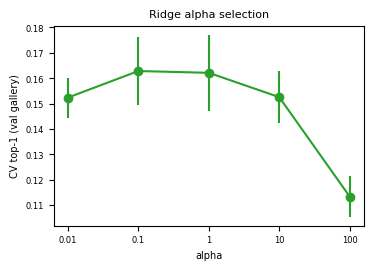

ridge                  cos 0.470 | R2 +0.193 | top1 0.152 [0.121,0.184] top5 0.438 top10 0.564 | med.rank 8 | within-top1 0.174 (chance 0.078)
shuffled-pairs ridge   cos 0.019 | R2 -0.173 | top1 0.002 [0.000,0.006] top5 0.024 top10 0.044 | med.rank 196 | within-top1 0.077 (chance 0.078)


In [17]:
ALPHAS = [0.01, 0.1, 1, 10, 100]
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(I_tr, Y_tr, g_tr))
cv_top1 = {a: [] for a in ALPHAS}
for tri, vai in folds:
    for a in ALPHAS:
        r = Ridge(alpha=a).fit(I_tr[tri], T_tr[tri])
        cv_top1[a].append(val_top1(r.predict(I_tr[vai]), T_tr[vai], g_tr[vai], Y_tr[vai]))
cv_mean = {a: float(np.mean(v)) for a, v in cv_top1.items()}
cv_std = {a: float(np.std(v)) for a, v in cv_top1.items()}
best_alpha = max(ALPHAS, key=lambda a: cv_mean[a])
for a in ALPHAS: print(f"alpha {a:<6} CV top-1 {cv_mean[a]:.3f} +- {cv_std[a]:.3f}")
print("chosen alpha:", best_alpha)

fig, ax = plt.subplots(figsize=(4, 2.6))
ax.errorbar(range(len(ALPHAS)), [cv_mean[a] for a in ALPHAS], [cv_std[a] for a in ALPHAS], marker="o", color=COLOR_IT)
ax.set_xticks(range(len(ALPHAS))); ax.set_xticklabels(ALPHAS); ax.set_xlabel("alpha"); ax.set_ylabel("CV top-1 (val gallery)")
ax.set_title("Ridge alpha selection"); plt.show()

ridge = Ridge(alpha=best_alpha).fit(I_tr, T_tr)
P_ridge = ridge.predict(I_te)
results["ridge"] = evaluate(P_ridge); show("ridge", results["ridge"])

# 1d) shuffled pairs: same ridge, but T_train rows randomly permuted (breaks pairing)
perm = np.random.default_rng(SEED).permutation(len(T_tr))
P = Ridge(alpha=best_alpha).fit(I_tr, T_tr[perm]).predict(I_te)
results["shuffled_ridge"] = evaluate(P); show("shuffled-pairs ridge", results["shuffled_ridge"])

## 3. MLP predictor (cosine loss) and 4. Contrastive predictor (InfoNCE)
Both use 512 -> 1024 -> 512 (GELU, dropout 0.1), AdamW (lr 1e-3, wd 1e-2), batch 128, <=300 epochs. 15% of TRAIN groups (GroupShuffleSplit) are held out for early stopping on validation top-1 (patience 20). The best-val-top-1 weights are restored. Final models therefore see 85% of the train rows.

In [18]:
def make_mlp():
    return nn.Sequential(nn.Linear(512, 1024), nn.GELU(), nn.Dropout(0.1), nn.Linear(1024, 512))

def cos_loss(P, Tt, gid):
    return (1 - F.cosine_similarity(P, Tt, dim=1)).mean()

def make_infonce(tau):
    def loss(P, Tt, gid):
        S = F.normalize(P, dim=1) @ F.normalize(Tt, dim=1).T / tau
        same = gid[:, None] == gid[None, :]
        mask = same & ~torch.eye(len(gid), dtype=torch.bool)   # same-target rows are not negatives
        S = S.masked_fill(mask, float("-inf"))
        lab = torch.arange(len(gid))
        return 0.5 * (F.cross_entropy(S, lab) + F.cross_entropy(S.T, lab))
    return loss

# group-aware train / val split of TRAIN
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
sub_i, val_i = next(gss.split(I_tr, Y_tr, g_tr))
assert not set(g_tr[sub_i]) & set(g_tr[val_i])
print("MLP train rows", len(sub_i), "val rows", len(val_i), "val groups", len(np.unique(g_tr[val_i])))
gid_all = np.unique(g_tr, return_inverse=True)[1]

def tt(x): return torch.tensor(x, dtype=torch.float32)

def train_predictor(loss_fn, max_epochs=300, patience=20, bs=128, seed=SEED):
    torch.manual_seed(seed)
    model = make_mlp()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    Xs, Ts, Gs = tt(I_tr[sub_i]), tt(T_tr[sub_i]), torch.tensor(gid_all[sub_i])
    Xv, Tv, Gv = tt(I_tr[val_i]), tt(T_tr[val_i]), torch.tensor(gid_all[val_i])
    gen = torch.Generator().manual_seed(seed)
    hist = dict(train=[], val=[], val_top1=[]); best = (-1, None, 0); bad = 0
    for ep in range(1, max_epochs + 1):
        model.train(); perm = torch.randperm(len(Xs), generator=gen); tot = 0
        for k in range(0, len(Xs), bs):
            b = perm[k:k + bs]
            if len(b) < 2: continue
            loss = loss_fn(model(Xs[b]), Ts[b], Gs[b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            Pv = model(Xv); vl = loss_fn(Pv, Tv, Gv).item()
        v1 = val_top1(Pv.numpy(), T_tr[val_i], g_tr[val_i], Y_tr[val_i])
        hist["train"].append(tot / len(Xs)); hist["val"].append(vl); hist["val_top1"].append(v1)
        if v1 > best[0]:
            best = (v1, {k_: v.clone() for k_, v in model.state_dict().items()}, ep); bad = 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best[1]); model.eval()
    return model, hist, best[2], best[0]

def predict(model, X):
    with torch.no_grad(): return model(tt(X)).numpy()

MLP train rows 1725 val rows 280 val groups 250


In [19]:
# 3. MLP, cosine loss
mlp, h_mlp, ep_mlp, v_mlp = train_predictor(cos_loss)
P_mlp = predict(mlp, I_te)
results["mlp"] = evaluate(P_mlp); show("MLP (cosine)", results["mlp"])
print("best epoch", ep_mlp, "of", len(h_mlp["train"]), "| val top-1", round(v_mlp, 3))

MLP (cosine)           cos 0.495 | R2 +0.158 | top1 0.141 [0.113,0.170] top5 0.398 top10 0.554 | med.rank 8 | within-top1 0.174 (chance 0.078)
best epoch 11 of 31 | val top-1 0.225


In [20]:
# 4. Contrastive, temperature chosen on validation top-1
runs = {}
for tau in [0.05, 0.07, 0.1]:
    m, h, ep, v = train_predictor(make_infonce(tau))
    runs[tau] = (m, h, ep, v)
    print(f"tau {tau}: best epoch {ep}/{len(h['train'])}, val top-1 {v:.3f}")
best_tau = max(runs, key=lambda t: runs[t][3])
con, h_con, ep_con, v_con = runs[best_tau]
P_con = predict(con, I_te)
results["contrastive"] = evaluate(P_con); show(f"contrastive tau={best_tau}", results["contrastive"])

tau 0.05: best epoch 52/72, val top-1 0.254
tau 0.07: best epoch 25/45, val top-1 0.257
tau 0.1: best epoch 17/37, val top-1 0.250
contrastive tau=0.07   cos 0.298 | R2 +0.084 | top1 0.162 [0.131,0.194] top5 0.455 top10 0.602 | med.rank 7 | within-top1 0.186 (chance 0.078)


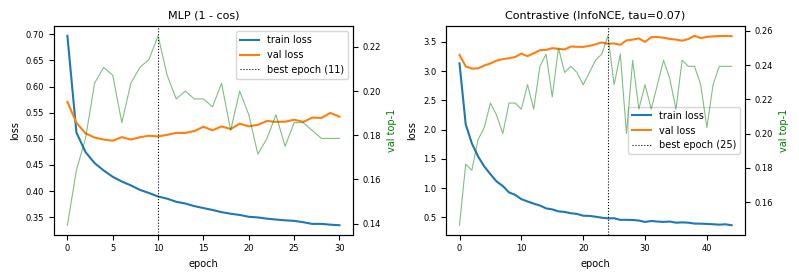

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(8, 2.8))
for ax, h, ep, title in [(axs[0], h_mlp, ep_mlp, "MLP (1 - cos)"), (axs[1], h_con, ep_con, f"Contrastive (InfoNCE, tau={best_tau})")]:
    ax.plot(h["train"], label="train loss"); ax.plot(h["val"], label="val loss")
    ax.axvline(ep - 1, color="k", ls=":", lw=0.8, label=f"best epoch ({ep})")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title(title)
    ax2 = ax.twinx(); ax2.plot(h["val_top1"], color="g", alpha=0.5, lw=0.8); ax2.set_ylabel("val top-1", color="g")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Downstream check: are the predicted targets useful?
Logistic probe (C=10, as chosen in step 4) trained on REAL T_train, applied to real and predicted T_test (predictions row-normalised, like real T).

In [22]:
probe = LogisticRegression(C=10, max_iter=5000).fit(T_tr, Y_tr)
downstream = {"real_T": float(probe.score(T_te, Y_te))}
for name, P in [("ridge", P_ridge), ("mlp", P_mlp), ("contrastive", P_con)]:
    downstream[name] = float(probe.score(rownorm(P), Y_te))
print(json.dumps(downstream, indent=1))

{
 "real_T": 0.8646464646464647,
 "ridge": 0.9131313131313131,
 "mlp": 0.8929292929292929,
 "contrastive": 0.9030303030303031
}


**Interpretation.** The probe only ever saw real T. If predicted T classifies about as well as, or better than, real T, the predictor is transferring label structure from I into T-space (I is a strong label carrier, ~0.93 in step 4, and the regression maps that structure into the region of T-space the probe understands). It does *not* by itself show the predictor recovers instance-specific target detail; the retrieval and within-class numbers above address that.

## 6. Reverse direction (ridge T -> I)
Same protocol; the gallery is all test I rows and the correct match is the row's own I.

In [23]:
def rev_eval(P, I_true, boot=False):
    Pn = rownorm(P); S = Pn @ I_true.T
    rank = 1 + (S > np.diag(S)[:, None]).sum(1)
    return dict(cos=float((Pn * I_true).sum(1).mean()), r2=float(r2_score(I_true, P, multioutput="variance_weighted")),
                top1=float((rank <= 1).mean()), top5=float((rank <= 5).mean()), top10=float((rank <= 10).mean()),
                median_rank=float(np.median(rank)), gallery_size=int(len(I_true)), chance_top1=float(1 / len(I_true)),
                **({"top1_ci": boot_ci(rank <= 1, boot_idx)} if boot else {}))

cv_rev = {a: [] for a in ALPHAS}
for tri, vai in folds:
    for a in ALPHAS:
        r = Ridge(alpha=a).fit(T_tr[tri], I_tr[tri])
        cv_rev[a].append(rev_eval(r.predict(T_tr[vai]), I_tr[vai])["top1"])
cv_rev_mean = {a: float(np.mean(v)) for a, v in cv_rev.items()}
alpha_rev = max(ALPHAS, key=lambda a: cv_rev_mean[a])
print({a: round(v, 3) for a, v in cv_rev_mean.items()}, "chosen", alpha_rev)
rev = rev_eval(Ridge(alpha=alpha_rev).fit(T_tr, I_tr).predict(T_te), I_te, boot=True)
results["ridge_reverse_T_to_I"] = rev
fwd = results["ridge"]
print(f"I->T: cos {fwd['cos']:.3f} top1 {fwd['top1']:.3f} (gallery {fwd['gallery_size']}, chance {fwd['chance_top1']:.4f})")
print(f"T->I: cos {rev['cos']:.3f} top1 {rev['top1']:.3f} (gallery {rev['gallery_size']}, chance {rev['chance_top1']:.4f}) CI {rev['top1_ci']}")

{0.01: 0.121, 0.1: 0.128, 1: 0.123, 10: 0.102, 100: 0.076} chosen 0.1
I->T: cos 0.470 top1 0.152 (gallery 414, chance 0.0024)
T->I: cos 0.524 top1 0.105 (gallery 495, chance 0.0020) CI [0.07878787878787878, 0.13131313131313133]


Note: the two directions use different galleries (414 unique T vs 495 I rows), so top-1 is only roughly comparable; cosine is the cleaner comparison but depends on how concentrated each space is.

## Sanity checks (stop conditions)

In [24]:
r = results
checks = {
    "ridge top-1 > raw I top-1": r["ridge"]["top1"] > r["raw_I"]["top1"],
    "ridge top-1 > shuffled top-1": r["ridge"]["top1"] > r["shuffled_ridge"]["top1"],
    "ridge top-1 CI lower > shuffled CI upper": r["ridge"]["top1_ci"][0] > r["shuffled_ridge"]["top1_ci"][1],
    "ridge within-class top-1 > chance": r["ridge"]["within_top1"] > r["ridge"]["within_chance"],
    "ridge within-class CI lower > chance": r["ridge"]["within_top1_ci"][0] > r["ridge"]["within_chance"],
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)

PASS ridge top-1 > raw I top-1
PASS ridge top-1 > shuffled top-1
PASS ridge top-1 CI lower > shuffled CI upper
PASS ridge within-class top-1 > chance
PASS ridge within-class CI lower > chance


## 7. Fig 4: Predicting the target from the context

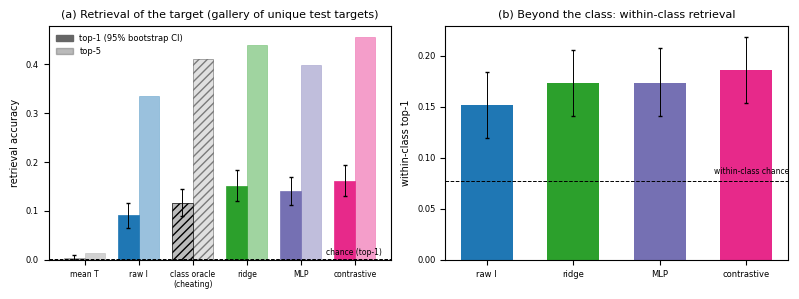

In [25]:
plt.rcParams.update({"font.size": 7, "axes.titlesize": 8, "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6})
COL = {"mean_T": "#999999", "raw_I": COLOR_I, "class_oracle": "#bbbbbb", "ridge": COLOR_IT, "mlp": "#7570b3", "contrastive": "#e7298a"}
NAMES = {"mean_T": "mean T", "raw_I": "raw I", "class_oracle": "class oracle\n(cheating)", "ridge": "ridge", "mlp": "MLP", "contrastive": "contrastive"}
keys = list(NAMES)
fig, axs = plt.subplots(1, 2, figsize=(8, 3))

ax = axs[0]; x = np.arange(len(keys)); w = 0.38
for j, k in enumerate(keys):
    hatch = "////" if k == "class_oracle" else None
    ci = results[k]["top1_ci"]; t1 = results[k]["top1"]
    ax.bar(j - w / 2, t1, w, color=COL[k], hatch=hatch, edgecolor="k" if hatch else COL[k], lw=0.5,
           yerr=[[t1 - ci[0]], [ci[1] - t1]], error_kw=dict(lw=0.7, capsize=1.5))
    ax.bar(j + w / 2, results[k]["top5"], w, color=COL[k], alpha=0.45, hatch=hatch, edgecolor="k" if hatch else COL[k], lw=0.5)
ax.axhline(results["ridge"]["chance_top1"], color="k", ls="--", lw=0.7)
ax.text(len(keys) - 0.5, results["ridge"]["chance_top1"] + 0.008, "chance (top-1)", ha="right", fontsize=5.5)
ax.set_xticks(x); ax.set_xticklabels([NAMES[k] for k in keys], fontsize=5.5)
ax.set_ylabel("retrieval accuracy"); ax.set_title("(a) Retrieval of the target (gallery of unique test targets)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="0.4", label="top-1 (95% bootstrap CI)"), Patch(color="0.4", alpha=0.45, label="top-5")], loc="upper left", frameon=False)

ax = axs[1]; kb = ["raw_I", "ridge", "mlp", "contrastive"]
for j, k in enumerate(kb):
    v = results[k]["within_top1"]; ci = results[k]["within_top1_ci"]
    ax.bar(j, v, 0.6, color=COL[k], yerr=[[v - ci[0]], [ci[1] - v]], error_kw=dict(lw=0.7, capsize=1.5))
ch = results["ridge"]["within_chance"]
ax.axhline(ch, color="k", ls="--", lw=0.7); ax.text(len(kb) - 0.5, ch + 0.006, "within-class chance", ha="right", fontsize=5.5)
ax.set_xticks(range(len(kb))); ax.set_xticklabels([NAMES[k] for k in kb])
ax.set_ylabel("within-class top-1"); ax.set_title("(b) Beyond the class: within-class retrieval")
plt.tight_layout()
fig.savefig("../figures/fig4_predictor.pdf", bbox_inches="tight")
fig.savefig("../figures/fig4_predictor.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Summary

In [26]:
summary = dict(
    seed=SEED,
    protocol=dict(n_train=int(len(Y_tr)), n_test=int(len(Y_te)), gallery_size=results["ridge"]["gallery_size"], n_boot=N_BOOT),
    metrics=results,
    ridge=dict(chosen_alpha=best_alpha, cv_top1_mean=cv_mean, cv_top1_std=cv_std),
    mlp=dict(best_epoch=int(ep_mlp), epochs_run=len(h_mlp["train"]), val_top1=v_mlp),
    contrastive=dict(best_epoch=int(ep_con), epochs_run=len(h_con["train"]), temperature=best_tau, val_top1=v_con,
                     val_top1_by_temperature={str(t): runs[t][3] for t in runs}),
    downstream_probe_acc=downstream,
    reverse_direction=dict(chosen_alpha=alpha_rev, cv_top1_mean=cv_rev_mean, T_to_I=results["ridge_reverse_T_to_I"],
                           I_to_T=results["ridge"]),
    sanity_checks={k: bool(v) for k, v in checks.items()},
)
Path("../results/step5_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "seed": 42,
  "protocol": {
    "n_train": 2005,
    "n_test": 495,
    "gallery_size": 414,
    "n_boot": 1000
  },
  "metrics": {
    "mean_T": {
      "cos": 0.0007196224178187549,
      "r2": -0.005269939079880714,
      "top1": 0.00404040404040404,
      "top5": 0.014141414141414142,
      "top10": 0.024242424242424242,
      "median_rank": 209.0,
      "within_top1": 0.07272727272727272,
      "within_chance": 0.0778041775966677,
      "gallery_size": 414,
      "chance_top1": 0.0024154589371980675,
      "top1_ci": [
        0.0,
        0.010101010101010102
      ],
      "within_top1_ci": [
        0.05247474747474747,
        0.09696969696969697
      ]
    },
    "raw_I": {
      "cos": 0.1819102019071579,
      "r2": -0.6425423622131348,
      "top1": 0.09090909090909091,
      "top5": 0.33535353535353535,
      "top10": 0.5111111111111111,
      "median_rank": 10.0,
      "within_top1": 0.15151515151515152,
      "within_chance": 0.0778041775966677,
      "gallery_size